<a href="https://colab.research.google.com/github/CalogeroGabriele/Artificial-Intelligence/blob/main/Supervised-Learning/Multivariate_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
import matplotlib.pyplot as plt
import numpy as np

In [66]:
np.random.seed(24)
m = 2000 #Number of examples
n = 2 #Number of features
X = 2 * np.random.rand(m,n)

#Valori reali (corretti) tetha che l'algoritmo di machine learning dovrà approssimare
theta = np.array([[3], [5]])
print(f"Contenuto theta: \n{theta}\n")
#Una normale lista come: theta = [3,5] avrebbe dimensioni (2,) , sarebbe ovvero monodimensionale
#ed inutilizzabile per il calcolo matriciale
print(f"Shape di theta: {theta.shape}\n")

#Questa non viene usata, è solo per dimostrare come scrivere una matrice anzichè un vettore (2,1) come quello soprastante
esempio_matrice = np.array([[1,2,3],[4,5,6]])
print(f"Contenuto matrice esempio: \n{esempio_matrice}\n")
print(f"Shape matrice: {esempio_matrice.shape}\n")

Y = 4 + X @ theta + 0.7*np.random.randn(m,1)
real_Y = 4 + X @ theta

print(f"\nContenuto Y con rumore: \n{Y}")

Contenuto theta: 
[[3]
 [5]]

Shape di theta: (2, 1)

Contenuto matrice esempio: 
[[1 2 3]
 [4 5 6]]

Shape matrice: (2, 3)


Contenuto Y con rumore: 
[[14.80990224]
 [11.64288596]
 [13.94519322]
 ...
 [17.31273467]
 [ 7.10862462]
 [16.66171744]]


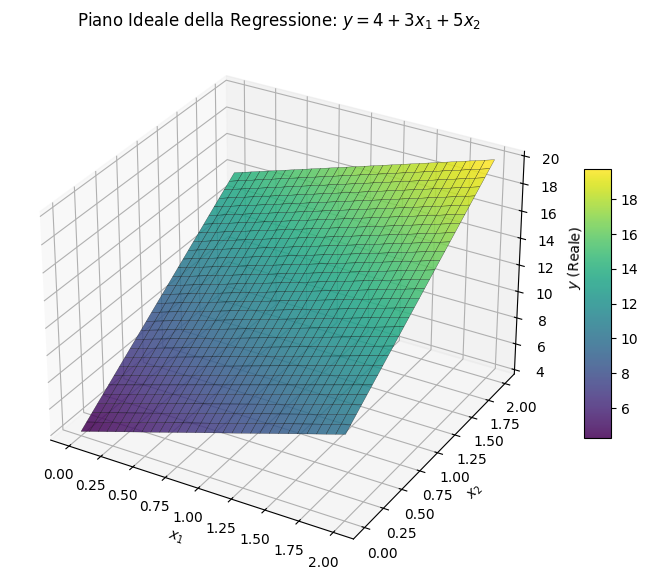

In [76]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# 3. Costruzione della griglia per il piano continuo real_Y
# Poiché X varia tra 0 e 2 (2 * rand), la griglia copre l'intervallo [0, 2]
x1_grid = np.linspace(0, 2, 30)
x2_grid = np.linspace(0, 2, 30)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)

# Equazione teorica: y = 4 + 3*x1 + 5*x2
# Nota: ricorda l'operatore di moltiplicazione '*' tra scalari e matrici
Y_plane = 4 + 3 * X1_mesh + 5 * X2_mesh

# 4. Disegno del solo piano ideale continuo (senza scatter plot dei punti rumorosi)
surf = ax.plot_surface(
    X1_mesh,
    X2_mesh,
    Y_plane,
    cmap="viridis",  # o color="red"
    alpha=0.85,
    edgecolor="k",
    linewidth=0.2
)

# Etichette e assi
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$y$ (Reale)")
ax.set_title("Piano Ideale della Regressione: $y = 4 + 3x_1 + 5x_2$")
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)

plt.show()

In [68]:
#Lavorando con tre theta (per via del bias) è necessario che il primo valore di X (campioni in input) sia 1
X_b = np.c_[np.ones((m, 1)), X]
print(f"Vettore X con 1 come valore iniziale per ognuna delle righe:\n {X_b}\n")
print(f"Shape di X_b: {X_b.shape}\n")

# Bias , theta1, theta2
initial_thetas = np.array([[0],[0],[0]])
print(f"Shape di initial_thetas: {initial_thetas.shape}\n")

print("X*theta => (5,3)*(3,1) = (5,1)")

Vettore X con 1 come valore iniziale per ognuna delle righe:
 [[1.         1.92003461 1.3990241 ]
 [1.         1.99973459 0.4401346 ]
 [1.         0.72211271 1.47968198]
 ...
 [1.         1.98059067 1.35184805]
 [1.         0.02195227 0.71424013]
 [1.         1.28475018 1.83275471]]

Shape di X_b: (2000, 3)

Shape di initial_thetas: (3, 1)

X*theta => (5,3)*(3,1) = (5,1)


In [69]:
#Equazione normale (forma normale) - GUARDARE LA SEMPLIFICAZIONE DELL'EQUAZIONE DALLE SLIDES
def MSE(X, thetas, Y):
  errors = X_b @ thetas - Y
  #Item permetti di ritornare solo il valore del MSE come scalare anzichè come elemento di un array numpy
  #Funziona solo se l'array contiene esattamente un elemento
  return ((errors.T @ errors)/len(X_b)).item()

MSE(X_b,initial_thetas, Y)

153.7792549873524

In [70]:
#Normal equation per trovare i valori theta

#Il calcolo dell inversa ha complessità computazionale pari a O(n^3), operazione proibitiva per un altro numero di features (n> 10.000)
final_theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y

print(final_theta)

[[3.95511483]
 [3.02357861]
 [5.01035734]]


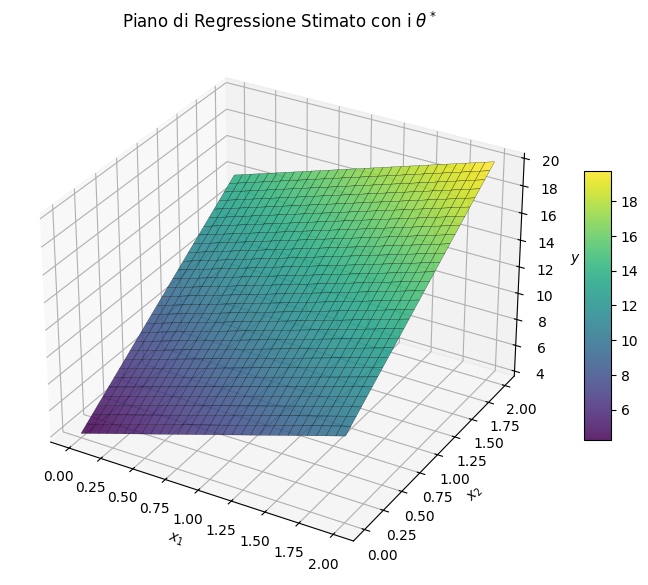

In [75]:
import matplotlib.pyplot as plt
import numpy as np

# Parametri ottimali calcolati
final_theta = np.array([[3.95511483], [3.02357861], [5.01035734]])

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# 1. Griglia per il piano
x1_grid = np.linspace(0, 2, 30)
x2_grid = np.linspace(0, 2, 30)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)

# 2. Quota del piano stimato: y = theta_0 + theta_1*x1 + theta_2*x2
Y_pred_mesh = (
    final_theta[0, 0] + final_theta[1, 0] * X1_mesh + final_theta[2, 0] * X2_mesh
)

# 3. Disegno del solo piano (pulito e ben visibile)
surf = ax.plot_surface(
    X1_mesh,
    X2_mesh,
    Y_pred_mesh,
    cmap="viridis",
    alpha=0.85,
    edgecolor="k",
    linewidth=0.2,
)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$y$")
ax.set_title("Piano di Regressione Stimato con i $\\theta^*$")
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)

plt.show()